# Continuous Optimization in Data Science: Assignment 3

**Group 3**

**Group members:**
- Simon Carlén
- Alvin Stallgård

## Q1.1 E-step: majorizer of the NLL

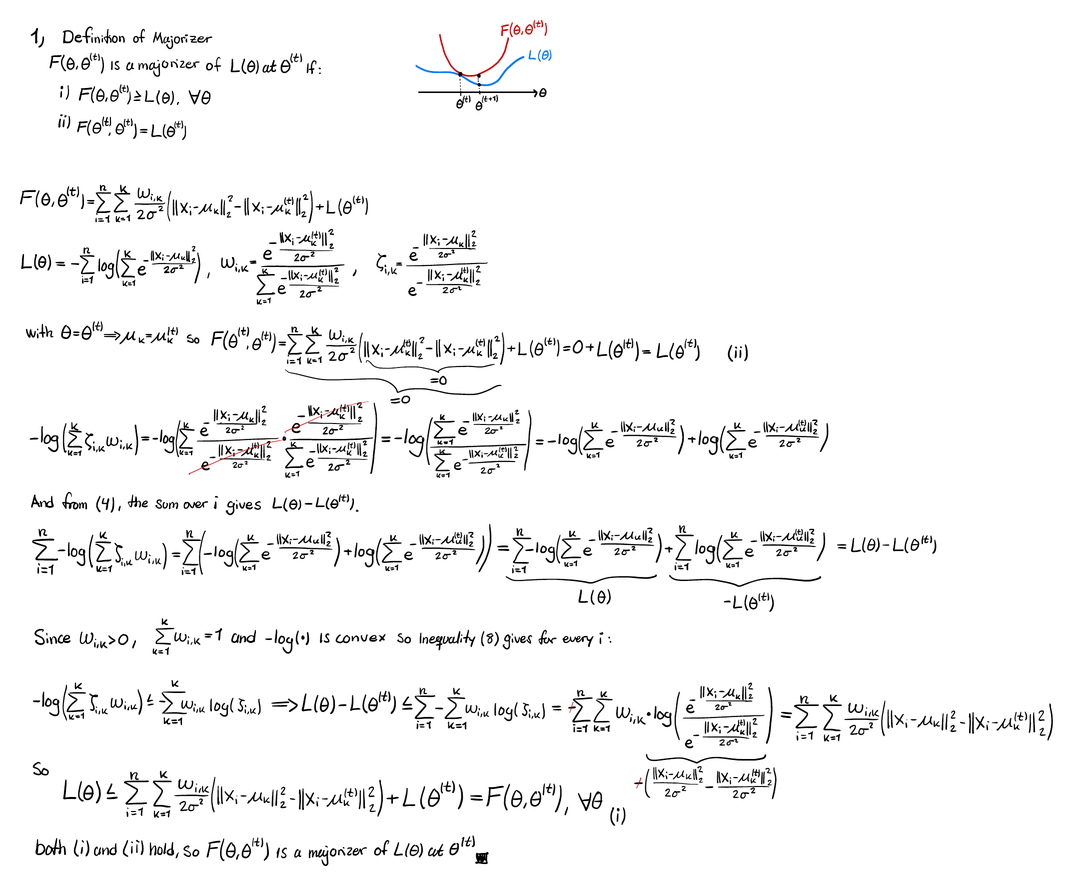

## Q1.2 M-step: centroid update

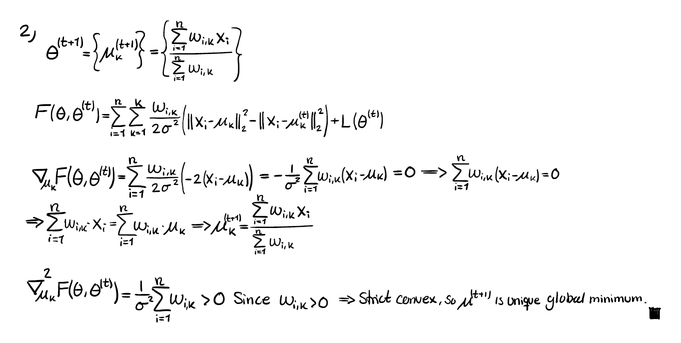

## Q1.3 EM clustering of credit card data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('CC GENERAL.csv').drop(columns='CUST_ID').dropna()
X = df.to_numpy()
X = (X - X.mean(axis=0)) / X.std(axis=0)
print(X.shape)

(8636, 17)


In [3]:
def EM_clustering(X, sigma, K):
    # Number of iterations
    iter_num = 10
    # d is the number of features and n is the number of the data points:
    (n, d) = X.shape
    # Initialize the K centroids randomly. Each row is a centroid.
    M = np.random.randn(K, d)
    # A vector that stores the NLL value in different iterations:
    value = np.zeros(iter_num)

    #start the EM loop:
    for t in range(iter_num):
        # Apply the E stape by calculating the omega_{i,k} coefficients
        omega_ = np.zeros((n, K))
        for i in range(n):
            for k in range(K):
                omega_[i, k] = -np.sum((X[i] - M[k])**2) / (2 * sigma**2)
            omega_[i, :] = np.exp(omega_[i, :] - np.max(omega_[i, :]))
            omega_[i, :] = omega_[i, :] / np.sum(omega_[i, :])

        # Apply the M step and obtain an update of M
        for k in range(K):
            M[k] = (omega_[:, k] @ X) / np.sum(omega_[:, k])

        # Calculate the NLL vale
        for i in range(n):
            a = np.zeros(K)
            for k in range(K):
                a[k] = -np.sum((X[i] - M[k])**2) / (2 * sigma**2)
            a_max = np.max(a)
            value[t] -= a_max + np.log(np.sum(np.exp(a - a_max)))

    return M, value

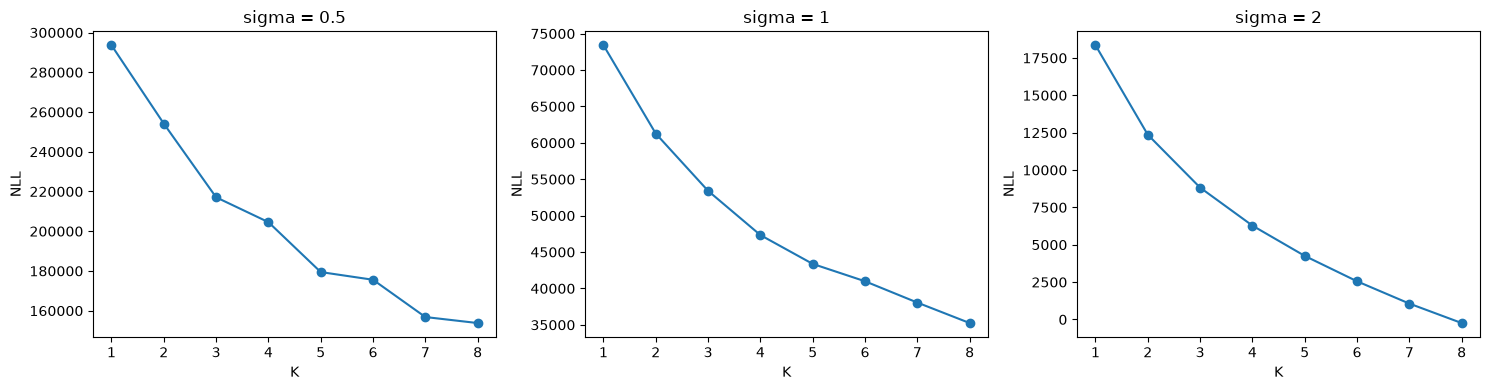

In [4]:
# (a) Optimal NLL vs number of clusters K for some values of sigma
sigmas = [0.5, 1, 2]
Ks = range(1, 9)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, sigma in zip(axes, sigmas):
    nll = []
    for K in Ks:
        M, value = EM_clustering(X, sigma, K)
        nll.append(value[-1])
    ax.plot(Ks, nll, 'o-')
    ax.set_title('sigma = ' + str(sigma))
    ax.set_xlabel('K')
    ax.set_ylabel('NLL')
plt.tight_layout()
plt.show()

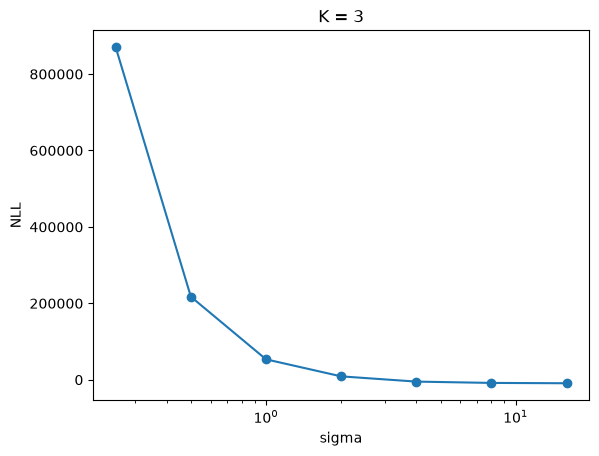

In [5]:
# (b) Optimal NLL vs sigma for K = 3
sigmas = [0.25, 0.5, 1, 2, 4, 8, 16]
nll = []
for sigma in sigmas:
    M, value = EM_clustering(X, sigma, 3)
    nll.append(value[-1])

plt.plot(sigmas, nll, 'o-')
plt.xscale('log')
plt.xlabel('sigma')
plt.ylabel('NLL')
plt.title('K = 3')
plt.show()

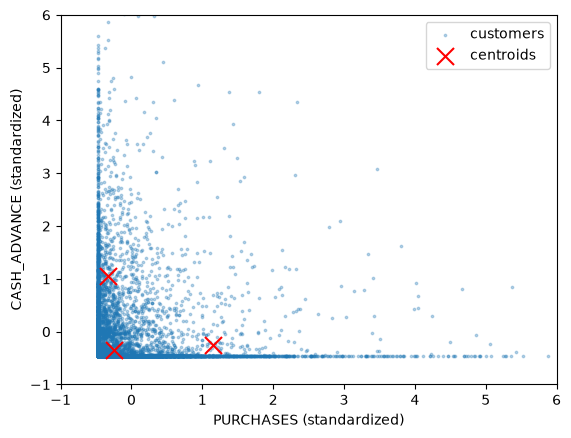

In [6]:
# (c) Scatter plot of two features with the trained centroids
f1 = 'PURCHASES'
f2 = 'CASH_ADVANCE'
j1 = df.columns.get_loc(f1)
j2 = df.columns.get_loc(f2)

M, value = EM_clustering(X, 1, 3)

plt.scatter(X[:, j1], X[:, j2], s=3, alpha=0.3, label='customers')
plt.scatter(M[:, j1], M[:, j2], c='red', marker='x', s=150, label='centroids')
plt.xlabel(f1 + ' (standardized)')
plt.ylabel(f2 + ' (standardized)')
plt.xlim(-1, 6)
plt.ylim(-1, 6)
plt.legend()
plt.show()

#### Report

We standardized all features before running EM since they have very different scales. Some are in the thousands and some are between 0 and 1.

**(a) Optimal NLL vs the number of clusters. Does it indicate a suitable number of clusters? Why?**

The NLL goes down every time we add a cluster, for all three values of $\sigma$. So the plot does not really indicate a suitable number of clusters. More centroids can always fit the data at least as well, and in the extreme case where $K = n$ every point would get its own centroid. That fits the data very well but is not a useful clustering. So the NLL alone can't be used to pick $K$, we would need something that also penalizes having many clusters or use what we know about the data.

**(b) Optimal NLL vs $\sigma$ for $K=3$. Explain the behavior.**

The NLL decreases when $\sigma$ increases. Every exponential term in the sum gets bigger when $\sigma$ grows, so the NLL as defined in (4) can only go down. For large $\sigma$ all terms are close to 1, the centroids end up close to the mean of the data and every point gets about the same weight 1/3 for each cluster. The NLL then gets close to $-n \log 3$ which is about $-9500$. This doesn't mean that a large $\sigma$ is better, because we dropped the constant $C$ which also depends on $\sigma$. If it was included the NLL would go up again for large $\sigma$.

**(c) 2D scatter plot of two features with the centroids.**

We used PURCHASES and CASH_ADVANCE with $K = 3$ and $\sigma = 1$. The three centroids roughly correspond to three types of customers. One group buys a lot, one buys little but uses more cash advance, and one has low activity in both. These groups could be targeted with different marketing. The plot only shows 2 of the 17 features, and some extreme customers are outside the axis limits.

## Q2.1 Projection operators

**(a) Projection onto the $\ell_2$ ball**

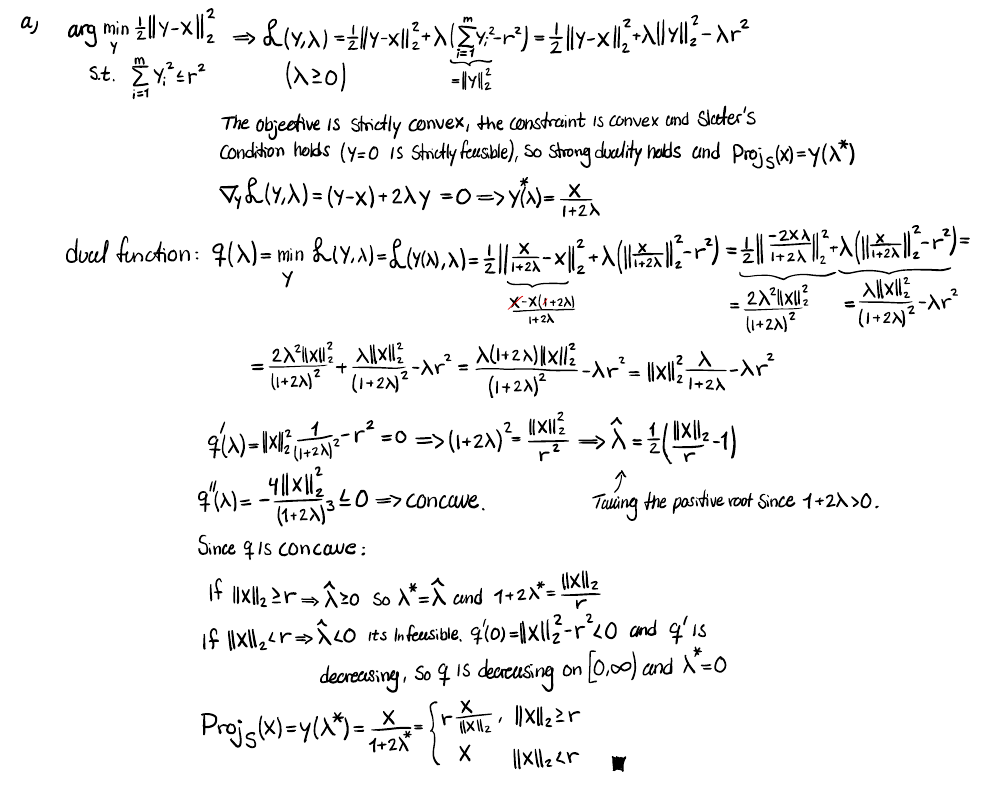

**(b) Shrinkage operator**

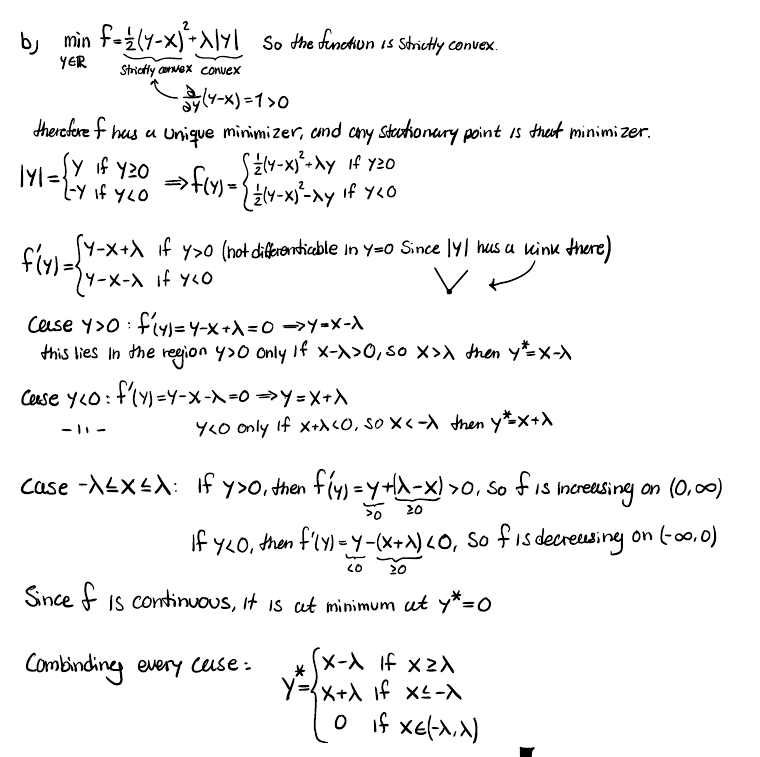

**(c) Projection onto the $\ell_1$ ball by dual gradient ascent**

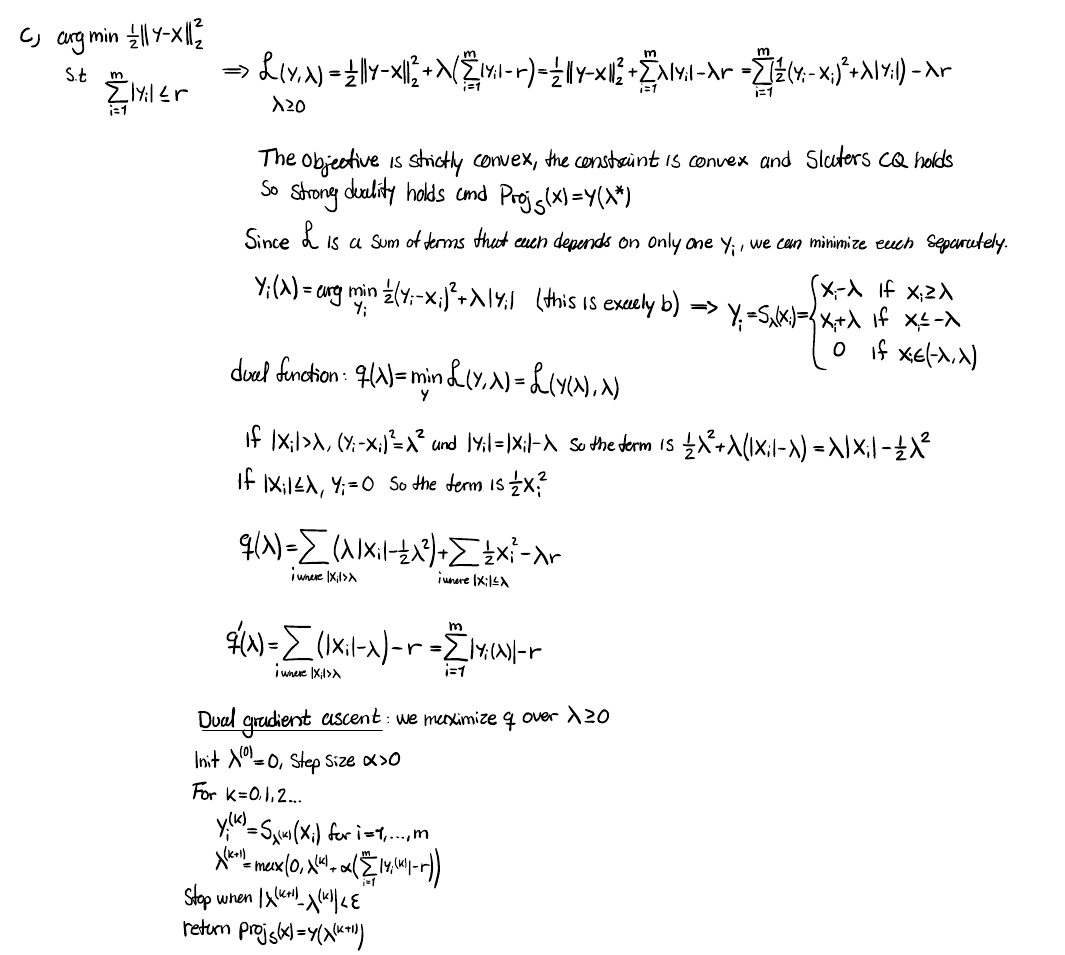

## Q2.2 Constrained least squares

In [7]:
npdata = np.loadtxt('Real estate.csv', delimiter=',', skiprows=1)
X_house = npdata[:, 1:7]
y_house = npdata[:, 7]
print(X_house.shape)

(414, 6)


In [8]:
def L1projection(x, r):
    # dual gradient ascent
    return x


def L2projection(x, r):
    return x


def LINFprojection(x, r):
    return x

In [9]:
# Check the projections on some random points

In [10]:
def PGD(X, y, projection, r, step, T):
    # gradient step on theta and mu, then project theta
    # store the objective value in every iteration
    return theta, mu, values

In [11]:
# (b) Objective value vs iterations for each constraint with r = 1

In [12]:
# (c) Trained coefficients vs the radius r for each constraint

#### Report

**(a) Effect of the step size.**

**(b) Objective value vs iterations for each constraint with $r=1$.**

**(c) Trained coefficients vs the radius $r$.**

## Q3.1 Firmly nonexpansive

## Q3.2 Non-expansive